In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist

from aspire.utils import gaussian_window, grid_2d, randn, trange
import tqdm
from overcrowding_utils import estimate_mean_naive, estimate_covar_naive, estimate_mean_ctfless, estimate_covar_ctfless, conv_diag, make_p_eff, estimate_psd
from utils_cwf_fast_batch import get_clean_mean_batch, get_clean_covar_batch, get_noise_var_batch
from scipy.sparse.linalg import LinearOperator, gmres
from scipy.signal import fftconvolve, oaconvolve
from aspire.source.micrograph import MicrographSimulation
from aspire.volume import Volume
from aspire.utils import Rotation, logging
from aspire.source import ArrayImageSource, Simulation
from scipy.ndimage import gaussian_filter
from scipy.interpolate import RegularGridInterpolator
from itertools import permutations
import time

logging.setConsoleLoggingLevel("WARNING")

psd_size = 48
dtype = np.float64

100.56779703341158
10156.539629426159


100%|██████████| 8/8 [00:00<00:00, 26.98it/s]


Time took for gmres: 0.016183880964914958 min
100.10017058853043
10062.09678390447


100%|██████████| 16/16 [00:05<00:00,  3.11it/s]


Time took for gmres: 0.15671631097793579 min
99.75084632712903
9990.479707026088


100%|██████████| 24/24 [00:29<00:00,  1.21s/it]


Time took for gmres: 0.7838980674743652 min
100.51594376607486
10140.31642819687


100%|██████████| 32/32 [01:36<00:00,  3.02s/it]


Time took for gmres: 2.5874003966649375 min


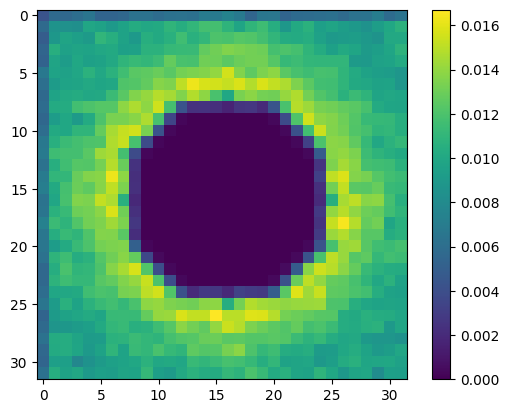

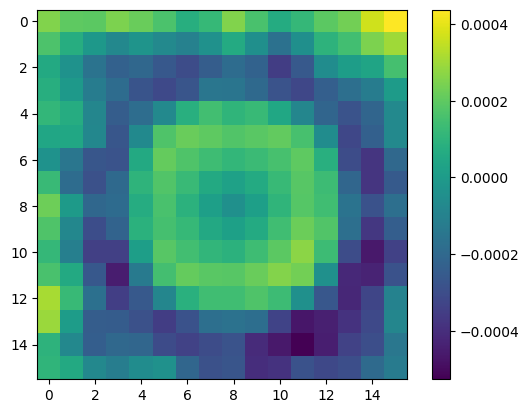

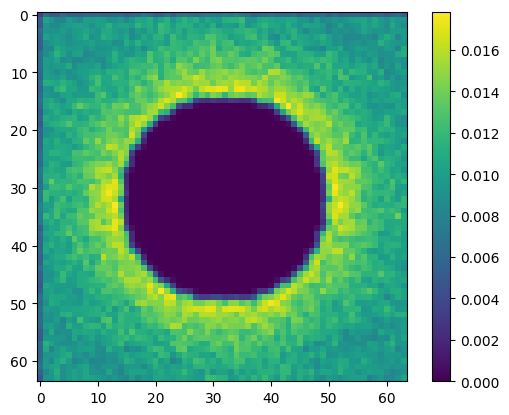

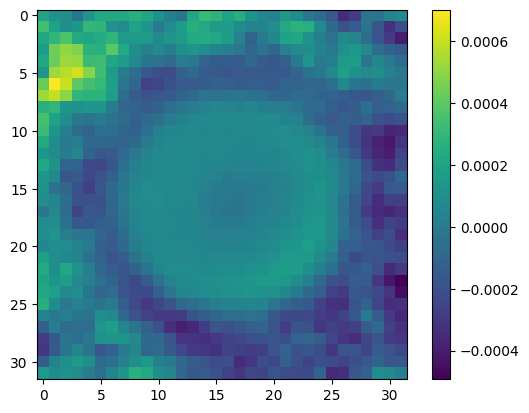

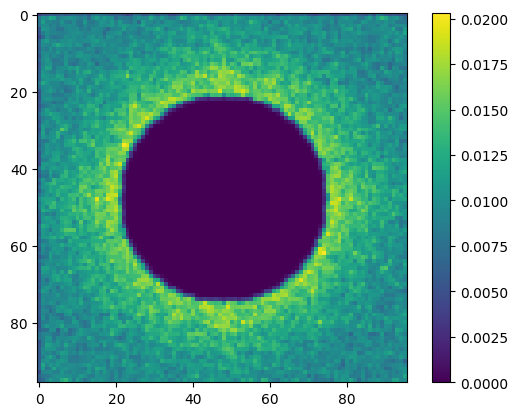

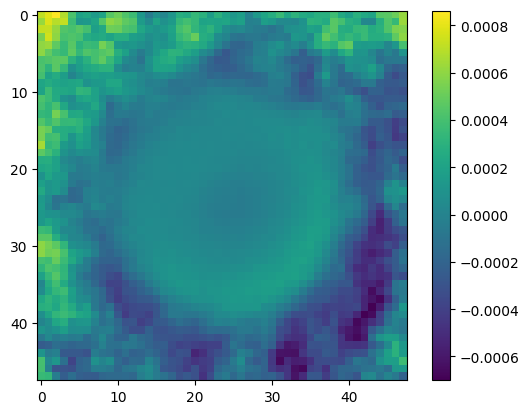

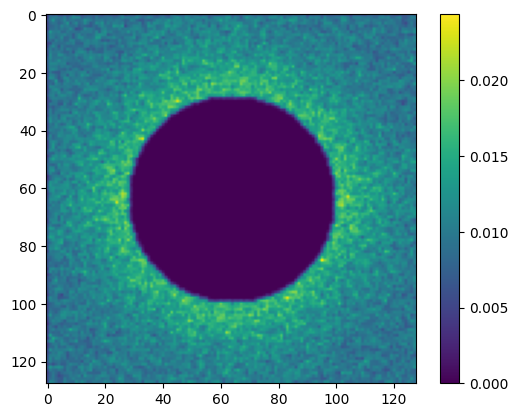

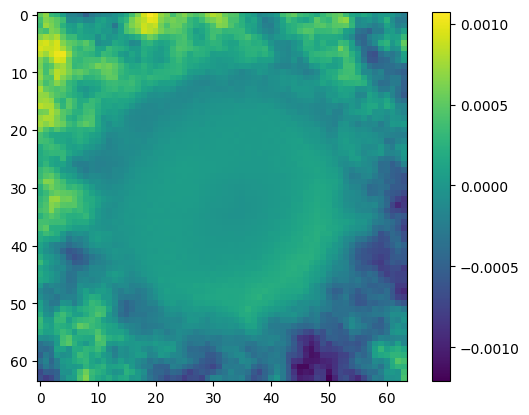

<Figure size 640x480 with 0 Axes>

In [2]:
num_micrographs = 800


psd_sizes = [16, 32, 48, 64]
dtype = np.float64

mean_errs = []
covar_errs = []
rng = np.random.default_rng(seed=1234)
for psd_size in psd_sizes:
    micrograph_size = psd_size * 10 
    vol = Volume.load('/tigress/CRYOEM/singerlab/az8940/10028/Refine3D/job003/run_class001.mrc').downsample(psd_size).astype(np.float64).asnumpy()[0]
    particles_per_micrograph = rng.integers(80, 121, num_micrographs)
    total_particles = np.sum(particles_per_micrograph)
    angles = Rotation.generate_random_rotations(total_particles, seed = 1234).angles
    alpha_numerator = np.sum(particles_per_micrograph * (particles_per_micrograph - 1))
    beta_numerator = np.sum(particles_per_micrograph * (particles_per_micrograph - 1) * (particles_per_micrograph - 2))
    alpha = alpha_numerator / total_particles
    beta = beta_numerator / total_particles
    print(alpha)
    print(beta)
    pixel_size = 1.34 * 360 / psd_size
    split_angles = np.split(angles, np.cumsum(particles_per_micrograph)[:-1])
    micro_srcs = []
    for i in range(num_micrographs):
        micro_srcs.append(MicrographSimulation(
                micrograph_size = micrograph_size,
                micrograph_count = 1,
                particles_per_micrograph=particles_per_micrograph[i],
                particle_amplitudes=psd_size,
                projection_angles = split_angles[i], 
                volume=Volume(vol),
                interparticle_distance = 9 * psd_size / 16,
                pixel_size = pixel_size,
                seed = 1234*i,
        )
                         )
    
    uncrowded_src = Simulation(
        L=psd_size,
        n=total_particles,
        vols=Volume(vol),
        amplitudes=psd_size,
        dtype=dtype,
        offsets = 0,
        pixel_size = pixel_size,
        angles = angles
    )
    
    img_array = []
    for i in range(num_micrographs):
        micrograph = micro_srcs[i].images[0].asnumpy()[0]
        for center in micro_srcs[i].centers[0]:
            x, y = center
            if x - psd_size//2 >= 0 and x+psd_size//2 < micrograph_size and y - psd_size//2 >= 0 and y + psd_size//2 < micrograph_size:
                img_array.append(micrograph[x-psd_size//2:x+psd_size//2, y-psd_size//2:y+psd_size//2])
    img_array = np.array(img_array)
    crowded_src = ArrayImageSource(img_array, pixel_size = pixel_size)
    center_offsets = rng.random((int(total_particles), 2)) - 0.5
    split_offsets = np.split(center_offsets, np.cumsum(particles_per_micrograph)[:-1])
    centers = [micro_srcs[i].centers[0].astype(np.float64) + split_offsets[i] for i in range(num_micrographs)]
    uncrowded_mean = estimate_mean_ctfless(uncrowded_src).real
    observed_covar = estimate_covar_ctfless(crowded_src)
    
    uncrowded_covar = estimate_covar_ctfless(uncrowded_src) 

    distances = []
    for i in range(num_micrographs):
        distances.append(pdist(centers[i]))
    distances = np.concatenate(distances) / psd_size
    
    raw_distances = []
    for i in range(num_micrographs):
        comp = centers[i][None, :, :] - centers[i][:, None, :]
        to_add = comp[~np.eye(len(centers[i]), dtype=bool)] / psd_size
        to_add = to_add[((np.abs(to_add[:, 0]) <= np.sqrt(2)) & (np.abs(to_add[:, 1]) <= np.sqrt(2)))]
        raw_distances.append(to_add)
    raw_distances = np.concatenate(raw_distances)
    
    
    raw_triples = []
    for m in range(num_micrographs):
        pts = centers[m]
        N = len(pts)
        for i in range(N):
            V = pts - pts[i]
            V = V[np.linalg.norm(V, axis = 1) > 1e-12]
    
            V1 = np.broadcast_to(V[:, None, :], (N-1, N-1, 2))
            V2 = np.broadcast_to(V[None, :, :], (N-1, N-1, 2))
            
            pair_tensor = np.concatenate((V1, V2), axis=-1)
            pair_mask = ~np.eye(len(V), dtype=bool)
            to_add = pair_tensor[pair_mask] / psd_size
            to_add = to_add[((np.abs(to_add[:, 0]) <= np.sqrt(2)) & (np.abs(to_add[:, 1]) <= np.sqrt(2)) & (np.abs(to_add[:, 2]) <= np.sqrt(2)) & (np.abs(to_add[:, 3]) <= np.sqrt(2)))]
            raw_triples.append(to_add)
    raw_triples = np.concatenate(raw_triples, axis=0)
    
    raw_triples2 = []
    for m in range(num_micrographs):
        pts = centers[m]
        N = len(pts)
        for i in range(N):
            V = pts - pts[i]
            V = V[np.linalg.norm(V, axis = 1) > 1e-12]
    
            V1 = np.broadcast_to(V[:, None, :], (N-1, N-1, 2))
            V2 = np.broadcast_to(V[None, :, :], (N-1, N-1, 2))
            
            pair_tensor = np.concatenate((V1, V2), axis=-1)
            pair_mask = ~np.eye(len(V), dtype=bool)
            to_add = pair_tensor[pair_mask] / psd_size
            raw_triples2.append(to_add)
    raw_triples2 = np.concatenate(raw_triples2, axis=0)

    # Estimate p_eff
    Nu = 1024
    u_edges = np.linspace(-np.sqrt(2), np.sqrt(2) , Nu+1)
    H, edges = np.histogramdd(
        raw_distances,
        bins=[u_edges, u_edges],
        density=True
    ) 
    cut_scaling = len(raw_distances) / alpha_numerator
    m_mean = 4
    Hs = gaussian_filter(
        H,
        sigma=[1,1],
        mode=['nearest','nearest']
    )
    uc  = u_edges[:-1]
    log_interp = RegularGridInterpolator(
        (uc, uc),
        Hs * cut_scaling,
        bounds_error=False,
        fill_value = 0,
        method='linear'
    )   
    g = np.linspace(-1, 1, 2 * m_mean * psd_size, endpoint = False) + 1e-8
    X1, X2 = np.meshgrid(
        g, g,
        indexing='ij'
    )
    pts = np.stack([
        X1.ravel(),
        X2.ravel()
    ], axis=1)
    vals = log_interp(pts).reshape(2 * m_mean * psd_size, 2 * m_mean * psd_size)
    eval_f_binning_hi = vals
    p_eff = make_p_eff(eval_f_binning_hi, psd_size, m_mean)
    
    plt.imshow(p_eff)
    plt.colorbar()
    plt.figure()
    
    observed_mean = estimate_mean_ctfless(crowded_src)
    
    mean_coords = np.arange(psd_size) - psd_size // 2
    X, Y = np.meshgrid(mean_coords, mean_coords, indexing="ij")
    
    mean_indices = np.where(np.linalg.norm(np.array([X, Y]), axis = 0, ord =np.inf) <= psd_size//2)
    
    mean_len = len(mean_indices[0])
    
    def matvec_mean_binning(v):
        v_ = np.zeros((psd_size, psd_size), dtype = np.complex128)
        v_[mean_indices] = v.flatten()
        
        term_hi = alpha * fftconvolve(p_eff, v_, mode = "full")[psd_size:-psd_size+1,psd_size:-psd_size+1] / (psd_size)**2
        return (v_ + term_hi)[mean_indices]
        
    mean_A_binning = LinearOperator(
        shape=(mean_len, mean_len),
        matvec=matvec_mean_binning,
        dtype=np.float64,
    )
    
    remean_binning = np.zeros((psd_size, psd_size), dtype = np.complex128)
    soln_binning, info = gmres(mean_A_binning, observed_mean[mean_indices], rtol = 1e-6)
    remean_binning[mean_indices] = soln_binning
    plt.imshow(remean_binning.real - uncrowded_mean)
    plt.colorbar()
    plt.figure()
    
    mean_err = np.linalg.norm(remean_binning.real - uncrowded_mean) / np.linalg.norm(uncrowded_mean) * 100
    
    # COVAR
    
    observed_covar = observed_covar.reshape(psd_size, psd_size, psd_size, psd_size)
    
    mean_diff_binning = observed_mean - remean_binning
    term2_binning = (mean_diff_binning.reshape(-1, 1) @ remean_binning.reshape(1, -1)).reshape(psd_size, psd_size, psd_size, psd_size)
    term3_binning = (remean_binning.reshape(-1, 1) @ mean_diff_binning.reshape(1, -1)).reshape(psd_size, psd_size, psd_size, psd_size)
            
    Nu = 160 #512#256#128

    u_edges = np.linspace(-np.sqrt(2), np.sqrt(2) , Nu+1)
    
    H, _ = np.histogramdd(
        raw_triples,
        bins=[u_edges, u_edges, u_edges, u_edges],
        density=True
    )
    
    cut_scaling = len(raw_triples) / beta_numerator
    H = gaussian_filter(H, sigma=0.75, axes=(0, 1), mode='nearest')
    H = gaussian_filter(H, sigma=0.75, axes=(2, 3), mode='nearest') * cut_scaling
    uc = 0.5 * (u_edges[:-1] + u_edges[1:])
    log_interp = RegularGridInterpolator(
        (uc, uc, uc, uc),
        H,
        bounds_error=False,
        fill_value = 0,
        method='linear'
    )
    n = 2 * psd_size
    g = np.linspace(-1, 1, n, endpoint=False) + 1e-8
    c_eff = np.empty((n, n, n, n), dtype=np.float64)
    chunk = 4 if psd_size <= 64 else 1
    for i in tqdm.tqdm(range(0, n, chunk)):
        gi = g[i:i+chunk]
        m = len(gi)
    
        pts = np.empty((m * n**3, 4), dtype=np.float64)
    
        pts[:, 0] = np.repeat(gi, n**3)
        pts[:, 1] = np.tile(np.repeat(g, n**2), m)
        pts[:, 2] = np.tile(np.repeat(g, n), m * n)
        pts[:, 3] = np.tile(g, m * n**2)
    
        c_eff[i:i+m] = log_interp(pts).reshape(m, n, n, n)
    del log_interp 
    del pts
    
    tmp = oaconvolve(
        c_eff,
        remean_binning[:, :, None, None],
        mode="valid",
        axes=(0, 1),
    )[1:, 1:, :, :]
    
    term5_binning_hi = oaconvolve(
        tmp,
        remean_binning[None, None, :, :],
        mode="valid",
        axes=(2, 3),
    )[:, :, 1:, 1:]
    
    coords = np.arange(psd_size) - psd_size // 2
    X, Y, Z, ZZ = np.meshgrid(coords, coords, coords, coords, indexing="ij")
    indices = np.where(np.linalg.norm(np.array([X, Y, Z, ZZ]), axis = 0, ord = np.inf) <= psd_size//2)
    
    def matvec_covar_binning(v):
        X = np.zeros((psd_size, psd_size, psd_size, psd_size), dtype=v.dtype)
    
        X[indices] = v.flatten()
    
        cov_hi = X # we will just use an effective diag_p_binning_hi instead of explicitly repeating
    
        term4_hi = conv_diag(cov_hi, p_eff)
    
        term4_hi *= alpha / psd_size**2
        return v + term4_hi[indices] 
        
    A_covar_binning = LinearOperator(
        shape=(len(indices[0]), len(indices[0])),
        matvec=matvec_covar_binning,
        dtype=np.float64,
    )
    
    t0 = time.time()
    soln_binning, info = gmres(A_covar_binning, (observed_covar - (term2_binning + term3_binning  + \
                        beta * term5_binning_hi / (psd_size)**4))[indices], rtol = 1e-6)
    print(f'Time took for gmres: {(time.time() - t0) / 60} min')
    recovar_binning = np.zeros((psd_size, psd_size, psd_size, psd_size), dtype=soln_binning.dtype)
    
    recovar_binning[indices] = soln_binning.flatten()
    est_uncrowded_outer_product = remean_binning.reshape(-1, 1) @ remean_binning.reshape(1, -1)

    true_outer_product = (uncrowded_mean.reshape(-1, 1) @ uncrowded_mean.reshape(1, -1)).reshape(uncrowded_covar.shape)
    crowded_outer_product = observed_mean.reshape(-1, 1) @ observed_mean.reshape(1, -1)
    covar_err = np.linalg.norm(recovar_binning.reshape(uncrowded_covar.shape) - uncrowded_covar - (est_uncrowded_outer_product - true_outer_product)) / np.linalg.norm(uncrowded_covar - true_outer_product.reshape(uncrowded_covar.shape)) * 100
    covar_errs.append(covar_err)
    mean_errs.append(mean_err)

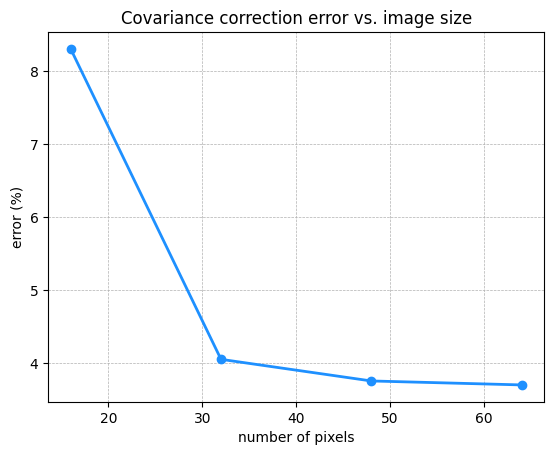

In [3]:
plt.plot(psd_sizes, covar_errs, "-o",lw=2.0,c="dodgerblue", label="covariance")
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.title(f"Covariance correction error vs. image size")
plt.ylabel("error (%)")
plt.xlabel("number of pixels")
plt.savefig("final_overcrowding_paper_figs/res3/cov_vs_n.pdf", bbox_inches = "tight")

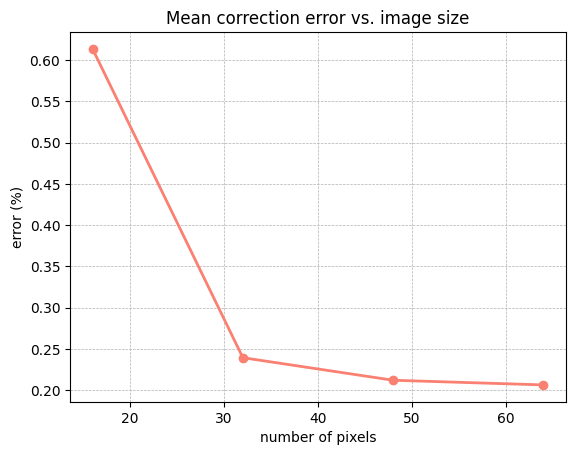

In [4]:
plt.plot(psd_sizes, mean_errs, "-o",lw=2.0, c="salmon", label = "mean")
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.title(f"Mean correction error vs. image size")
plt.ylabel("error (%)")
plt.xlabel("number of pixels")
plt.savefig("final_overcrowding_paper_figs/res3/mean_vs_n.pdf", bbox_inches = "tight")

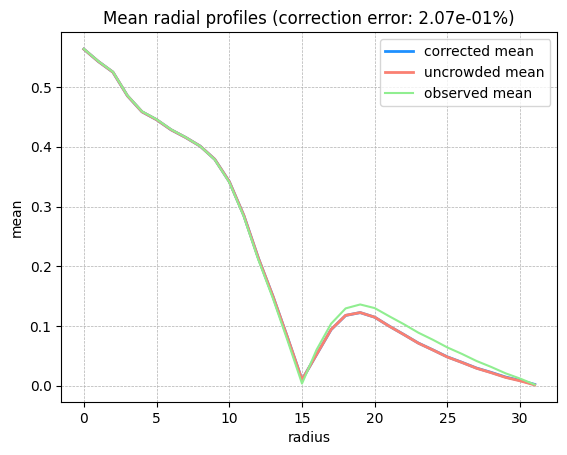

In [5]:
plt.plot(np.abs(remean_binning[psd_size//2, psd_size//2:]), lw=2.0,label = "corrected mean", color="dodgerblue")
plt.plot(np.abs(uncrowded_mean[psd_size//2, psd_size//2:]), lw=2.0, label = "uncrowded mean", color="salmon")
plt.plot(np.abs(observed_mean[psd_size//2, psd_size//2:]), label = "observed mean", color="lightgreen")
plt.grid(True, which='major', linestyle='--', linewidth=0.5)
plt.title(f"Mean radial profiles (correction error: {mean_err:.2e}%)")
plt.xlabel("radius")
plt.ylabel("mean")
plt.legend()
plt.savefig("final_overcrowding_paper_figs/res3/means.pdf",bbox_inches = "tight")

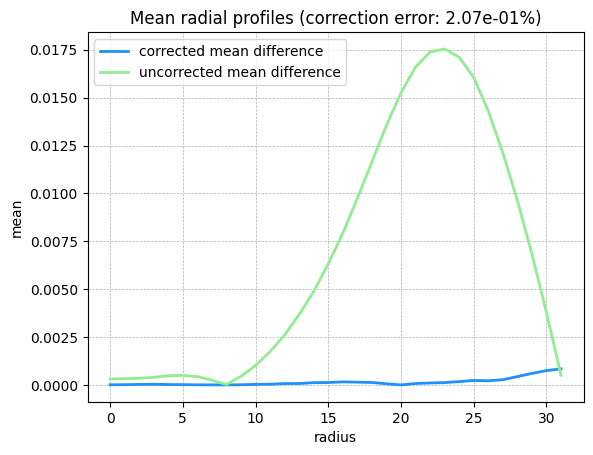

In [6]:
plt.plot(np.abs((remean_binning - uncrowded_mean)[psd_size//2, psd_size//2:]), lw=2.0,label = "corrected mean difference", color="dodgerblue")
plt.plot(np.abs((observed_mean - uncrowded_mean)[psd_size//2, psd_size//2:]), lw=2.0, label = "uncorrected mean difference", color="lightgreen")
plt.grid(True, which='major', linestyle='--', linewidth=0.5)
plt.title(f"Mean radial profiles (correction error: {mean_err:.2e}%)")
plt.xlabel("radius")
plt.ylabel("mean")
plt.legend()
plt.savefig("final_overcrowding_paper_figs/res3/mean_diff.pdf",bbox_inches = "tight")

In [7]:
def save_image(img, fname, cmap="gray"):
    fig, ax = plt.subplots(figsize=(4, 4))
    ax.imshow(img, cmap=cmap)
    ax.set_axis_off()
    fig.subplots_adjust(left=0, right=1, top=1, bottom=0)
    fig.savefig(fname, format="pdf", bbox_inches="tight", pad_inches=0)
    plt.close(fig)

micrograph = micro_srcs[0].images[0].asnumpy()[0]
save_image(micrograph, "final_overcrowding_paper_figs/res3/micrograph.pdf")

particles = crowded_src.images[:2].asnumpy()
save_image(particles[0], "final_overcrowding_paper_figs/res3/particle_1.pdf")
save_image(particles[1], "final_overcrowding_paper_figs/res3/particle_2.pdf")